# Fidel CNN — Fine-tune for Canvas Drawing Style

## What this notebook does

The CNN classifier was trained on **scanned handwriting forms** — clean 25×25 images from paper.
In the web app, users draw on a **canvas** — different stroke thickness, angles, and style.

This notebook:
1. Reuses the **exact same preprocessing from fidelwriting1(3).ipynb** — same data loading, same CHARS_FULL mapping, same invert logic
2. Adds **canvas-style augmentations** (stroke dilation/erosion, rotation, perspective, blur), applied in two phases: light first, then full strength, so the pretrained model isn't shocked into forgetting what it already learned
3. Fine-tunes from your existing `fidel_cnn_best.pt` checkpoint, with **early stopping** and **mixed precision** so more epochs fit in the time budget
4. **Fails loudly and clearly** if the checkpoint can't be found, instead of silently falling back to training 287 classes from scratch (this was the bug behind the ~28% accuracy run)

**Setup:**
- Attach dataset: `yaredoffice/amharic-handwritten-characters`
- Upload `fidel_cnn_best.pt` as a dataset input named `fidel-cnn`
- Accelerator: GPU T4 x1
- Runtime: ~10-15 minutes (more epochs than before, but early stopping keeps it from running needlessly long)


In [4]:
import shutil
import os

# Define the working directory path
folder_path = '/kaggle/working'

# Delete all contents inside /kaggle/working but keep the main folder
for item in os.listdir(folder_path):
    item_path = os.path.join(folder_path, item)
    if os.path.isfile(item_path) or os.path.islink(item_path):
        os.unlink(item_path)
    elif os.path.isdir(item_path):
        shutil.rmtree(item_path)


## Step 1 — Setup & data (from fidelwriting1(3).ipynb)

In [5]:
import os, glob, random, hashlib, re
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter
import cv2

os.environ['CUDA_VISIBLE_DEVICES'] = '0'

# Auto-detect dataset path (same as original notebook)
DATA_DIR = None
for candidate in [
    '/kaggle/input/amharic-handwritten-characters/OCR_dataset/train',
    '/kaggle/input/datasets/yaredoffice/amharic-handwritten-characters/OCR_dataset/train',
]:
    if os.path.exists(candidate):
        DATA_DIR = candidate
        break

assert DATA_DIR, 'Attach yaredoffice/amharic-handwritten-characters dataset'
parent_dir = os.path.dirname(DATA_DIR)

class_dirs = sorted(os.listdir(DATA_DIR), key=lambda x: int(x))
print(f'DATA_DIR: {DATA_DIR}')
print(f'Total classes: {len(class_dirs)}')

DATA_DIR: /kaggle/input/datasets/yaredoffice/amharic-handwritten-characters/OCR_dataset/train
Total classes: 287


In [6]:
# ── Exact cells from fidelwriting1(3).ipynb ───────────────────────────────────
# Build hash map from train_form folder (used to recover character labels)

def file_hash(path):
    return hashlib.md5(open(path, 'rb').read()).hexdigest()

form_dir   = os.path.join(parent_dir, 'train_form')
form_files = os.listdir(form_dir)
form_hashes = {file_hash(os.path.join(form_dir, f)): f for f in form_files}
print(f'{len(form_files)} files in train_form, {len(form_hashes)} unique hashes')

def extract_char(formname):
    m = re.match(r'^(\S+)\s+form\s+\d+\.png$', formname)
    return m.group(1) if m else None

def hash_lookup(fid):
    files = glob.glob(os.path.join(DATA_DIR, fid, '*'))
    found = [extract_char(form_hashes[file_hash(p)]) for p in files if file_hash(p) in form_hashes]
    found = [c for c in found if c]
    top   = Counter(found).most_common(1)
    return top[0] if top else (None, 0)

14063 files in train_form, 14063 unique hashes


In [7]:
# ── Build CHARS_FULL — exact same logic as fidelwriting1(3).ipynb ─────────────
CHARS_FULL = []
for fid_num in range(287):
    char, count = hash_lookup(str(fid_num))
    CHARS_FULL.append(char)

print(len(CHARS_FULL), 'classes mapped')
print('any None left?', any(c is None for c in CHARS_FULL))

# Show the 7 orders × 34 families structure
family_groups = {}
for fid in range(238):
    family_groups.setdefault(fid % 34, []). append(fid)

print('\nFamily structure (7 orders × 34 families):')
for fam in range(34):
    chars = [CHARS_FULL[f] for f in family_groups[fam]]
    print(f'  family {fam:2d}: {" ".join(chars)}')

287 classes mapped
any None left? False

Family structure (7 orders × 34 families):
  family  0: ሀ ሁ ሂ ሃ ሄ ህ ሆ
  family  1: ለ ሉ ሊ ላ ሌ ል ሎ
  family  2: ሐ ሑ ሒ ሓ ሔ ሕ ሖ
  family  3: መ ሙ ሚ ማ ሜ ም ሞ
  family  4: ሠ ሡ ሢ ሣ ሤ ሥ ሦ
  family  5: ረ ሩ ሪ ራ ሬ ር ሮ
  family  6: ሰ ሱ ሲ ሳ ሴ ስ ሶ
  family  7: ሸ ሹ ሺ ሻ ሼ ሽ ሾ
  family  8: ቀ ቁ ቂ ቃ ቄ ቅ ቆ
  family  9: በ ቡ ቢ ባ ቤ ብ ቦ
  family 10: ቨ ቩ ቪ ቫ ቬ ቭ ቮ
  family 11: ተ ቱ ቲ ታ ቴ ት ቶ
  family 12: ቸ ቹ ቺ ቻ ቼ ች ቾ
  family 13: ኀ ኁ ኂ ኃ ኄ ኅ ኆ
  family 14: ነ ኑ ኒ ና ኔ ን ኖ
  family 15: ኘ ኙ ኚ ኛ ኜ ኝ ኞ
  family 16: አ ኡ ኢ ኣ ኤ እ ኦ
  family 17: ከ ኩ ኪ ካ ኬ ክ ኮ
  family 18: ኸ ኹ ኺ ኻ ኼ ኽ ኾ
  family 19: ወ ዉ ዊ ዋ ዌ ው ዎ
  family 20: ዐ ዑ ዒ ዓ ዔ ዕ ዖ
  family 21: ዘ ዙ ዚ ዛ ዜ ዝ ዞ
  family 22: ዠ ዡ ዢ ዣ ዤ ዥ ዦ
  family 23: የ ዩ ዪ ያ ዬ ይ ዮ
  family 24: ደ ዱ ዲ ዳ ዴ ድ ዶ
  family 25: ጀ ጁ ጂ ጃ ጄ ጅ ጆ
  family 26: ገ ጉ ጊ ጋ ጌ ግ ጎ
  family 27: ጠ ጡ ጢ ጣ ጤ ጥ ጦ
  family 28: ጨ ጩ ጪ ጫ ጬ ጭ ጮ
  family 29: ጰ ጱ ጲ ጳ ጴ ጵ ጶ
  family 30: ጸ ጹ ጺ ጻ ጼ ጽ ጾ
  family 31: ፀ ፁ ፂ ፃ ፄ ፅ ፆ
  family 32: ፈ ፉ ፊ ፋ ፌ ፍ ፎ
  family 33: ፐ ፑ ፒ ፓ ፔ ፕ 

/tmp/ipykernel_672/2694630562.py:13: UserWarning: Glyph 4608 (\N{ETHIOPIC SYLLABLE HA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_672/2694630562.py:13: UserWarning: Glyph 4616 (\N{ETHIOPIC SYLLABLE LA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_672/2694630562.py:13: UserWarning: Glyph 4624 (\N{ETHIOPIC SYLLABLE HHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_672/2694630562.py:13: UserWarning: Glyph 4632 (\N{ETHIOPIC SYLLABLE MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_672/2694630562.py:13: UserWarning: Glyph 4640 (\N{ETHIOPIC SYLLABLE SZA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_672/2694630562.py:13: UserWarning: Glyph 4648 (\N{ETHIOPIC SYLLABLE RA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_672/2694630562.py:13: UserWarning: Glyph 4656 (\N{ETHIOPIC SYLLABLE SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout

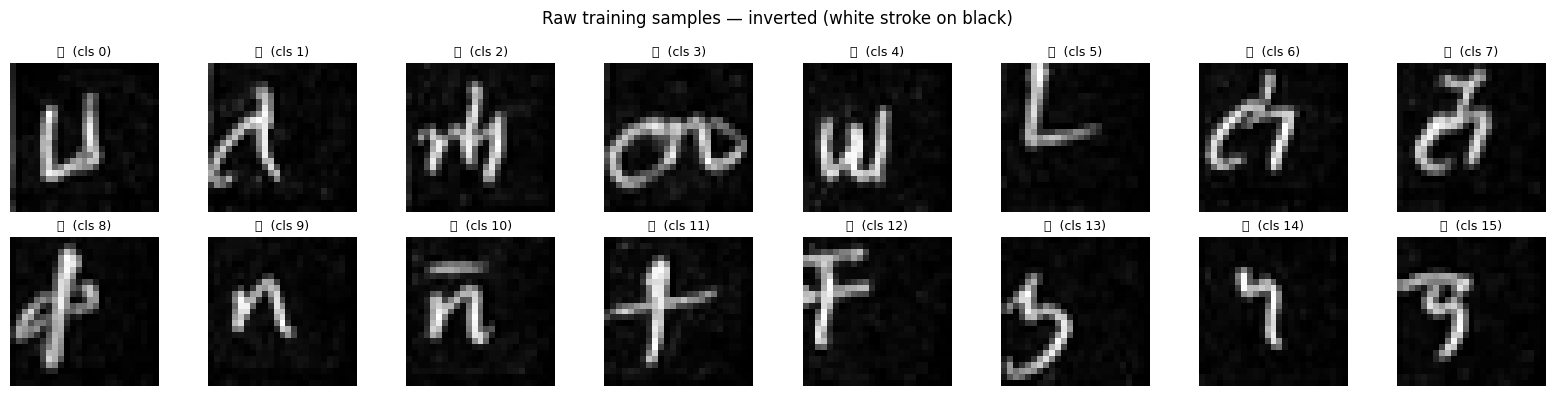

In [8]:
# ── Visualise raw training samples (same display as original notebook) ─────────
# Show one sample from each of the first 16 classes, inverted (white stroke on black)
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i, ax in enumerate(axes.flat):
    fid   = str(i)
    files = glob.glob(os.path.join(DATA_DIR, fid, '*'))
    p     = sorted(files)[0]
    raw   = 255 - np.array(Image.open(p).convert('L'))  # invert — same as original
    ax.imshow(raw, cmap='gray', interpolation='nearest')
    ax.set_title(f'{CHARS_FULL[i]}  (cls {i})', fontsize=9)
    ax.axis('off')
plt.suptitle('Raw training samples — inverted (white stroke on black)', fontsize=12)
plt.tight_layout()
plt.show()

## Step 2 — Canvas-style augmentations (two-phase: light → full)

In [9]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torch.optim.lr_scheduler import CosineAnnealingLR

IMG_SIZE   = 25
device     = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

# ── Custom augmentations that simulate canvas drawing ─────────────────────────
class RandomDilate:
    """Thicken strokes — simulates user drawing with a thicker brush."""
    def __init__(self, max_kernel=2, p=0.5):
        self.max_kernel = max_kernel
        self.p = p
    def __call__(self, img):
        if random.random() > self.p:
            return img
        arr    = np.array(img)
        k      = random.randint(1, self.max_kernel)
        kernel = np.ones((2*k+1, 2*k+1), np.uint8)
        return Image.fromarray(cv2.dilate(arr, kernel, iterations=1))

class RandomErode:
    """Thin strokes — simulates user drawing with a thinner/faster stroke."""
    def __init__(self, p=0.3):
        self.p = p
    def __call__(self, img):
        if random.random() > self.p:
            return img
        arr    = np.array(img)
        kernel = np.ones((3, 3), np.uint8)
        return Image.fromarray(cv2.erode(arr, kernel, iterations=1))

# ── Two-phase augmentation ─────────────────────────────────────────────────────
# Phase "light": gentle perturbations only — lets the model adapt from clean
# scanned-form strokes to slightly-varied canvas strokes WITHOUT destroying
# the features it already learned in pretraining.
# Phase "full": the original, stronger canvas-style augmentation — builds
# robustness once the model has re-anchored on the new domain.
def make_train_transform(strength='light'):
    if strength == 'light':
        return transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            RandomDilate(max_kernel=1, p=0.3),
            RandomErode(p=0.15),
            transforms.RandomAffine(
                degrees=8, translate=(0.08, 0.08),
                scale=(0.9, 1.1), shear=5, fill=0,
            ),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.5], std=[0.5]),
        ])
    else:  # 'full'
        return transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            RandomDilate(max_kernel=2, p=0.5),      # variable stroke thickness
            RandomErode(p=0.3),                      # thin strokes
            transforms.RandomAffine(               # tilt, shift, scale
                degrees=15, translate=(0.15, 0.15),
                scale=(0.8, 1.2), shear=10, fill=0,
            ),
            transforms.RandomPerspective(distortion_scale=0.2, p=0.4),  # drawing angle
            transforms.RandomApply(                # LANCZOS anti-aliasing simulation
                [transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))], p=0.4
            ),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.5], std=[0.5]),
        ])

train_tf = make_train_transform('light')  # start gentle; ramped up in the training loop

# Validation: no augmentation
val_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5]),
])

print('Augmentation pipeline ready (starting in light-augmentation phase).')


device: cuda
Augmentation pipeline ready (starting in light-augmentation phase).


/tmp/ipykernel_672/526305419.py:24: UserWarning: Glyph 4656 (\N{ETHIOPIC SYLLABLE SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 4656 (\N{ETHIOPIC SYLLABLE SA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


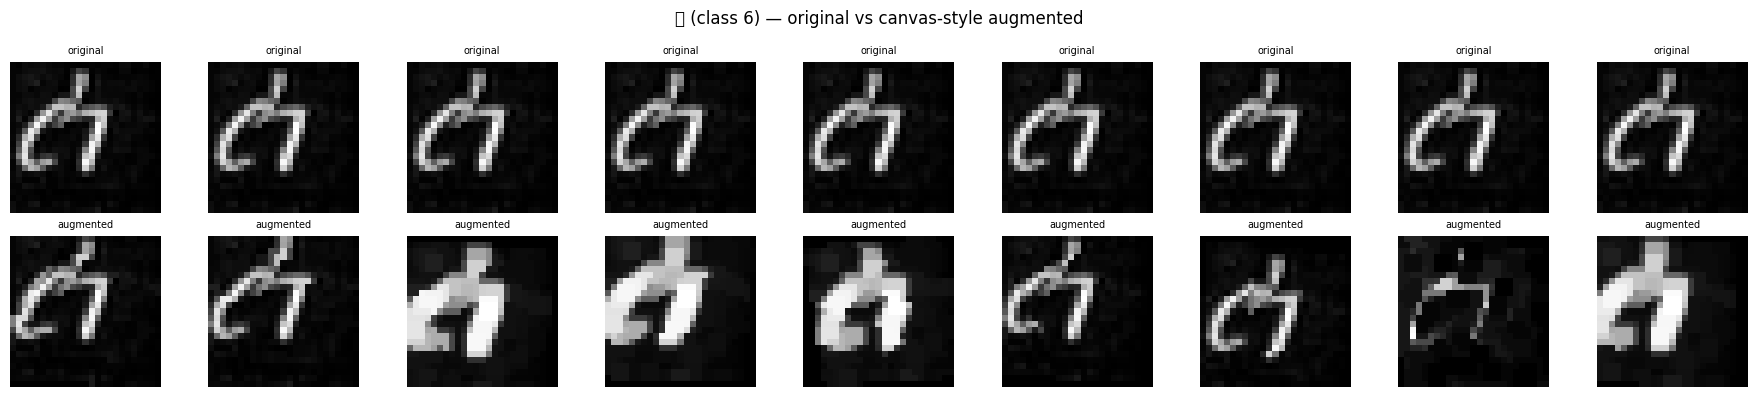

Top row = what the model was originally trained on
Bottom row = what it will see during fine-tuning (simulates real canvas drawing)


In [10]:
# ── Show what augmented samples look like vs raw ───────────────────────────────
# Pick ሰ (class 6) — a common character to draw
sample_fid  = 6
sample_path = sorted(glob.glob(os.path.join(DATA_DIR, str(sample_fid), '*')))[0]
raw_img     = Image.open(sample_path).convert('RGBA').convert('L')
raw_img     = Image.fromarray(255 - np.array(raw_img))  # invert

fig, axes = plt.subplots(2, 9, figsize=(18, 4))

# top row: original
for ax in axes[0]:
    ax.imshow(np.array(raw_img.resize((IMG_SIZE, IMG_SIZE))), cmap='gray', interpolation='nearest')
    ax.set_title('original', fontsize=7)
    ax.axis('off')

# bottom row: augmented
for ax in axes[1]:
    aug = train_tf(raw_img)
    ax.imshow(aug.squeeze().numpy() * 0.5 + 0.5, cmap='gray')
    ax.set_title('augmented', fontsize=7)
    ax.axis('off')

plt.suptitle(f'ሰ (class {sample_fid}) — original vs canvas-style augmented', fontsize=12)
plt.tight_layout()
plt.show()
print('Top row = what the model was originally trained on')
print('Bottom row = what it will see during fine-tuning (simulates real canvas drawing)')

## Step 3 — Dataset & DataLoader

In [11]:
BATCH_SIZE = 64
SEED       = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

class FidelDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples   = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        # RGBA → L → invert — same preprocessing as original notebook
        img = Image.open(path).convert('RGBA').convert('L')
        img = Image.fromarray(255 - np.array(img))
        if self.transform:
            img = self.transform(img)
        return img, label


# Build sample list
all_samples = []
for folder in sorted(os.listdir(DATA_DIR), key=lambda x: int(x)):
    label = int(folder)
    fp    = os.path.join(DATA_DIR, folder)
    for fname in os.listdir(fp):
        if fname.lower().endswith(('.png', '.jpg', '.jpeg')):
            all_samples.append((os.path.join(fp, fname), label))

# Image-level split (same image always in same split — no leakage)
all_paths   = list({p for p, _ in all_samples})
random.shuffle(all_paths)
n           = len(all_paths)
train_paths = set(all_paths[:int(n * 0.8)])
val_paths   = set(all_paths[int(n * 0.8):])

train_samples = [(p, l) for p, l in all_samples if p in train_paths]
val_samples   = [(p, l) for p, l in all_samples if p in val_paths]
print(f'Total: {len(all_samples)}  Train: {len(train_samples)}  Val: {len(val_samples)}')

train_loader = DataLoader(FidelDataset(train_samples, train_tf),
                          batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(FidelDataset(val_samples,   val_tf),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
print('DataLoaders ready.')

Total: 13776  Train: 11020  Val: 2756
DataLoaders ready.


## Step 4 — Model (same architecture as fidel_cnn_kaggle.ipynb)

In [12]:
NUM_CLASSES = 287

class FidelCNN(nn.Module):
    def __init__(self, num_classes=287):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 3 * 3, 512), nn.ReLU(), nn.Dropout(0.4),
            nn.Linear(512, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))


model = FidelCNN(NUM_CLASSES).to(device)

# ── Robust checkpoint search ───────────────────────────────────────────────────
# IMPORTANT: the earlier version of this cell only checked two hardcoded paths.
# If your dataset-input folder name didn't match exactly, it silently fell
# through to training 287 classes FROM SCRATCH for 30 epochs — which is why
# accuracy was stuck around 28%. This version searches recursively under
# /kaggle/input and /kaggle/working for the checkpoint file by name, so a
# mismatched folder name can't cause a silent scratch-training run again.
CKPT_FILENAME = 'fidel_cnn_best.pt'
BASE_CKPT = None

search_roots = ['/kaggle/input', '/kaggle/working']
found_candidates = []
for root in search_roots:
    if os.path.exists(root):
        found_candidates += glob.glob(os.path.join(root, '**', CKPT_FILENAME), recursive=True)

if found_candidates:
    BASE_CKPT = found_candidates[0]
    if len(found_candidates) > 1:
        print(f'Found {len(found_candidates)} matches for {CKPT_FILENAME}, using: {BASE_CKPT}')
        print('Other matches:', found_candidates[1:])
else:
    print(f'⚠️  Could not find {CKPT_FILENAME} anywhere under /kaggle/input or /kaggle/working.')
    print('    Listing /kaggle/input contents for debugging:')
    if os.path.exists('/kaggle/input'):
        for entry in os.listdir('/kaggle/input'):
            print('   ', entry)

if BASE_CKPT:
    EPOCHS = 40
    LR     = 2e-4   # lower LR — don't overwrite what was already learned
else:
    EPOCHS = 30
    LR     = 1e-3

# ── Two-phase fine-tuning schedule ────────────────────────────────────────────
# Phase 1 (light augmentation): re-anchor the pretrained model on canvas-style
# strokes without destroying what it already learned.
# Phase 2 (full augmentation): build robustness to the full range of canvas
# drawing variation.
PHASE1_EPOCHS = max(5, EPOCHS // 3) if BASE_CKPT else 0
EARLY_STOP_PATIENCE = 10

if BASE_CKPT:
    ckpt = torch.load(BASE_CKPT, map_location=device)
    model.load_state_dict(ckpt['model_state'])
    base_acc = ckpt.get('val_acc', 0.0)
    print(f'✓ Loaded checkpoint: {BASE_CKPT}')
    print(f'  Base val_acc: {base_acc:.4f}')
    print(f'  Fine-tuning plan: {PHASE1_EPOCHS} epochs light-aug, '
          f'then {EPOCHS - PHASE1_EPOCHS} epochs full-aug (lr={LR}, early-stop patience={EARLY_STOP_PATIENCE})')
else:
    base_acc = 0.0
    print(f'Training from scratch ({EPOCHS} epochs) — accuracy will NOT reach 85-90% this way.')
    print('Re-run after attaching fidel_cnn_best.pt as a Kaggle dataset input.')

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler    = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))


✓ Loaded checkpoint: /kaggle/input/datasets/fenetefera/fidel-cnn/fidel_cnn_best.pt
  Base val_acc: 0.7347
  Fine-tuning plan: 13 epochs light-aug, then 27 epochs full-aug (lr=0.0002, early-stop patience=10)


/tmp/ipykernel_672/2736970225.py:87: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler    = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))


## Step 5 — Fine-tuning loop (two-phase augmentation + early stopping + mixed precision)

In [13]:
OUT_DIR = '/kaggle/working/fidel-cnn-finetuned'
os.makedirs(OUT_DIR, exist_ok=True)

def accuracy(outputs, labels):
    return (outputs.argmax(1) == labels).float().mean().item()

best_val_acc   = base_acc
epochs_no_improve = 0
train_dataset  = train_loader.dataset  # so we can swap its transform between phases

for epoch in range(1, EPOCHS + 1):

    # ── Switch from light to full augmentation at the phase boundary ─────────
    if BASE_CKPT and epoch == PHASE1_EPOCHS + 1:
        train_dataset.transform = make_train_transform('full')
        print(f'--- Switching to FULL canvas augmentation at epoch {epoch} ---')

    model.train()
    t_loss, t_acc = 0.0, 0.0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
            out  = model(imgs)
            loss = criterion(out, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        t_loss += loss.item()
        t_acc  += accuracy(out, labels)
    t_loss /= len(train_loader)
    t_acc  /= len(train_loader)

    model.eval()
    v_loss, v_acc = 0.0, 0.0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
                out    = model(imgs)
                v_loss += criterion(out, labels).item()
            v_acc  += accuracy(out, labels)
    v_loss /= len(val_loader)
    v_acc  /= len(val_loader)
    scheduler.step()

    phase = 'light' if (BASE_CKPT and epoch <= PHASE1_EPOCHS) else 'full'
    print(f'Epoch {epoch:02d}/{EPOCHS} [{phase}-aug] | '
          f'train loss={t_loss:.4f} acc={t_acc:.4f} | '
          f'val loss={v_loss:.4f} acc={v_acc:.4f}')

    if v_acc > best_val_acc:
        best_val_acc = v_acc
        epochs_no_improve = 0
        torch.save({
            'epoch': epoch, 'model_state': model.state_dict(),
            'val_acc': v_acc, 'num_classes': NUM_CLASSES, 'img_size': IMG_SIZE,
        }, os.path.join(OUT_DIR, 'fidel_cnn_finetuned_best.pt'))
        print(f'  ✓ best saved  val_acc={v_acc:.4f}')
    else:
        epochs_no_improve += 1
        if epoch > PHASE1_EPOCHS and epochs_no_improve >= EARLY_STOP_PATIENCE:
            print(f'  ⏹ early stopping — no improvement in {EARLY_STOP_PATIENCE} epochs')
            break

print(f'\nFine-tuning complete. Best val accuracy: {best_val_acc:.4f}')
if best_val_acc < 0.85:
    print('Below target (85-90%). If this happened even with the checkpoint loading '
          'correctly (check the log above for "Loaded checkpoint"), try: more PHASE1 '
          'epochs, a lower LR, or checking the checkpoint really matches this exact '
          'FidelCNN architecture / 287-class mapping.')


/tmp/ipykernel_672/3520867677.py:23: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
/tmp/ipykernel_672/3520867677.py:39: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):


Epoch 01/40 [light-aug] | train loss=3.4030 acc=0.3351 | val loss=2.1900 acc=0.7418
  ✓ best saved  val_acc=0.7418
Epoch 02/40 [light-aug] | train loss=3.3315 acc=0.3515 | val loss=2.1784 acc=0.7464
  ✓ best saved  val_acc=0.7464
Epoch 03/40 [light-aug] | train loss=3.2730 acc=0.3647 | val loss=2.2066 acc=0.7351
Epoch 04/40 [light-aug] | train loss=3.2565 acc=0.3744 | val loss=2.1708 acc=0.7393
Epoch 05/40 [light-aug] | train loss=3.2233 acc=0.3718 | val loss=2.1439 acc=0.7479
  ✓ best saved  val_acc=0.7479
Epoch 06/40 [light-aug] | train loss=3.1827 acc=0.3890 | val loss=2.1609 acc=0.7358
Epoch 07/40 [light-aug] | train loss=3.1664 acc=0.3961 | val loss=2.1413 acc=0.7525
  ✓ best saved  val_acc=0.7525
Epoch 08/40 [light-aug] | train loss=3.1572 acc=0.4001 | val loss=2.1267 acc=0.7564
  ✓ best saved  val_acc=0.7564
Epoch 09/40 [light-aug] | train loss=3.1316 acc=0.4037 | val loss=2.1132 acc=0.7582
  ✓ best saved  val_acc=0.7582
Epoch 10/40 [light-aug] | train loss=3.1283 acc=0.4030 | v

## Step 6 — Evaluation & visual results

In [14]:
ckpt = torch.load(os.path.join(OUT_DIR, 'fidel_cnn_finetuned_best.pt'), map_location=device)
model.load_state_dict(ckpt['model_state'])
model.eval()
print(f"Best epoch: {ckpt['epoch']}  val_acc: {ckpt['val_acc']:.4f}")

top1, top5, total = 0, 0, 0
with torch.no_grad():
    for imgs, labels in val_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        out      = model(imgs)
        top5_idx = out.topk(5, dim=1).indices
        top1    += (top5_idx[:, 0] == labels).sum().item()
        top5    += (top5_idx == labels.unsqueeze(1)).any(dim=1).sum().item()
        total   += labels.size(0)

print(f'Val  Top-1: {top1/total:.4f}   Top-5: {top5/total:.4f}   ({total} samples)')

Best epoch: 11  val_acc: 0.7592
Val  Top-1: 0.7707   Top-5: 0.9724   (2756 samples)


/tmp/ipykernel_672/3548200235.py:20: UserWarning: Glyph 4608 (\N{ETHIOPIC SYLLABLE HA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_672/3548200235.py:20: UserWarning: Glyph 4616 (\N{ETHIOPIC SYLLABLE LA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_672/3548200235.py:20: UserWarning: Glyph 4658 (\N{ETHIOPIC SYLLABLE SI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_672/3548200235.py:20: UserWarning: Glyph 4662 (\N{ETHIOPIC SYLLABLE SO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_672/3548200235.py:21: UserWarning: Glyph 4608 (\N{ETHIOPIC SYLLABLE HA}) missing from font(s) DejaVu Sans.
  plt.savefig(os.path.join(OUT_DIR, 'finetuned_predictions.png'), dpi=100)
/tmp/ipykernel_672/3548200235.py:21: UserWarning: Glyph 4616 (\N{ETHIOPIC SYLLABLE LA}) missing from font(s) DejaVu Sans.
  plt.savefig(os.path.join(OUT_DIR, 'finetuned_predictions.png'), dpi=100)
/tmp/ipykernel_672/3548200235.py:2

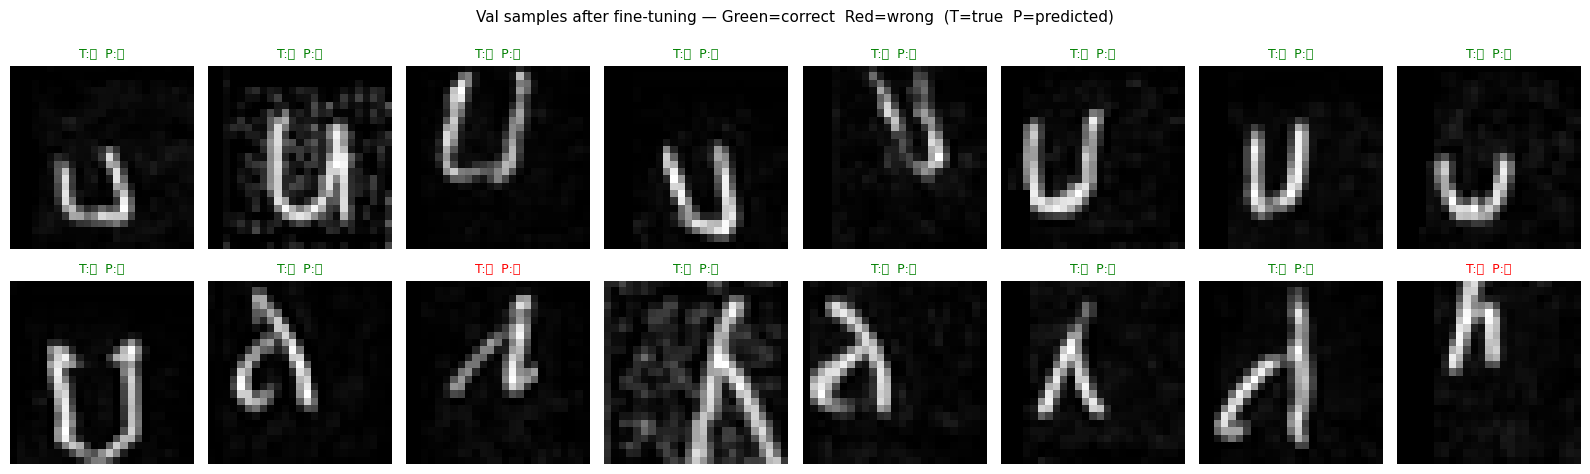

In [15]:
# ── Visual results — same display style as original notebook ──────────────────
# Show 16 val samples: green = correct, red = wrong, title shows true vs predicted char
sample_imgs, sample_labels = next(iter(val_loader))
sample_imgs_dev = sample_imgs[:16].to(device)

with torch.no_grad():
    preds = model(sample_imgs_dev).argmax(1).cpu()

fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for i, ax in enumerate(axes.flat):
    img_np = sample_imgs[i].squeeze().numpy() * 0.5 + 0.5
    true_c = CHARS_FULL[sample_labels[i].item()]
    pred_c = CHARS_FULL[preds[i].item()]
    color  = 'green' if preds[i] == sample_labels[i] else 'red'
    ax.imshow(img_np, cmap='gray', interpolation='nearest')
    ax.set_title(f'T:{true_c}  P:{pred_c}', color=color, fontsize=9)
    ax.axis('off')

plt.suptitle('Val samples after fine-tuning — Green=correct  Red=wrong  (T=true  P=predicted)', fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'finetuned_predictions.png'), dpi=100)
plt.show()

## Step 7 — Export for inference

In [16]:
import shutil

export_path = os.path.join(OUT_DIR, 'fidel_cnn_inference1.pt')
torch.save({
    'model_state':    model.state_dict(),
    'num_classes':    NUM_CLASSES,
    'img_size':       IMG_SIZE,
    'normalize_mean': 0.5,
    'normalize_std':  0.5,
}, export_path)

print(f'Exported: {export_path}')
print(f'Size: {os.path.getsize(export_path)/1e6:.1f} MB')

shutil.make_archive(os.path.join(OUT_DIR, 'fidel_cnn_inference'), 'zip',
                    OUT_DIR, 'fidel_cnn_inference1.pt')

print('\n=== DONE ===')
print('Download: Kaggle → Output → fidel-cnn-finetuned/fidel_cnn_inference1.zip')
print('Then: cp fidel_cnn_inference.pt ~/aifidel/ && python3 app.py')

Exported: /kaggle/working/fidel-cnn-finetuned/fidel_cnn_inference1.pt
Size: 4.1 MB

=== DONE ===
Download: Kaggle → Output → fidel-cnn-finetuned/fidel_cnn_inference1.zip
Then: cp fidel_cnn_inference.pt ~/aifidel/ && python3 app.py
